# Lecture 15 notebook: who trades and what it costs

This notebook replays Lecture 15 on the tape of Lecture 12. Every figure and number of the lecture comes from a script in `scripts/`, next to this
notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | Does one-sided flow predict the price? | §2 |
| 2 | Sweeps and absorption | §3 |
| 3 | Cascades: fuel and spark | §4 |
| 4 | What a trade costs | §5 |
| 5 | Resting orders: fills, misses, the cut-off and re-posting | §6 |
| 6 | Capacity: impact and funding | §7 |
| 7 | A test of your own | §9.2 |

**Before you start.** Lecture 12's notebook must have built the tape for October 2021 to September 2026. Results go to `data/interim/l15`;
figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never overwritten. Three steps read or download large amounts of data and
are off by default (`RUN_HEAVY` in §0); with the flag off, the notebook uses their saved output in `data/interim`.

## 0. Settings

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, Markdown, display

HERE = Path.cwd()
SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS), str(HERE.parent / "13-bars-not-cut-by-time" / "scripts"), str(HERE.parent / "12-tick-data-the-tape"), str(HERE.parents[1])]
import tape
OUT = tape.ROOT / "interim" / "l15"

RUN_HEAVY = False      # True reruns: the extraction of all sweeps from the tape (about 40 minutes), the download of Binance's five-minute open interest
                       # (1,826 small files), and the best bid and ask of 80 days (8 GB of downloads, many hours); False uses their saved output

pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", "the folder in the environment variable TAPE_ROOT" if os.environ.get("TAPE_ROOT") else "data/ at the top of the repository")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    """Run a script of scripts/ in a fresh process; figures to figures/ as nb_*, results to data/interim/l15."""
    t0 = time.time()
    env = {**os.environ, "TAPE_ROOT": str(tape.ROOT), "L15_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def result(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: the folder in the environment variable TAPE_ROOT
free memory: 4.2 GB of 16.9 GB


## 1. Does one-sided flow predict the price?

Lecture §2. Windows of 1, 5 and 30 minutes sorted into fifths by net aggressive buying: the return during the window and over the next, by
volatility regime; the strongest flow split by its relation to the slower trend; and three scheduled releases. Figures 15_01 to 15_03.

l15_flow.py: 3 s


l15_flow_matrix.py: 4 s


l15_s2_charts.py: 14 s


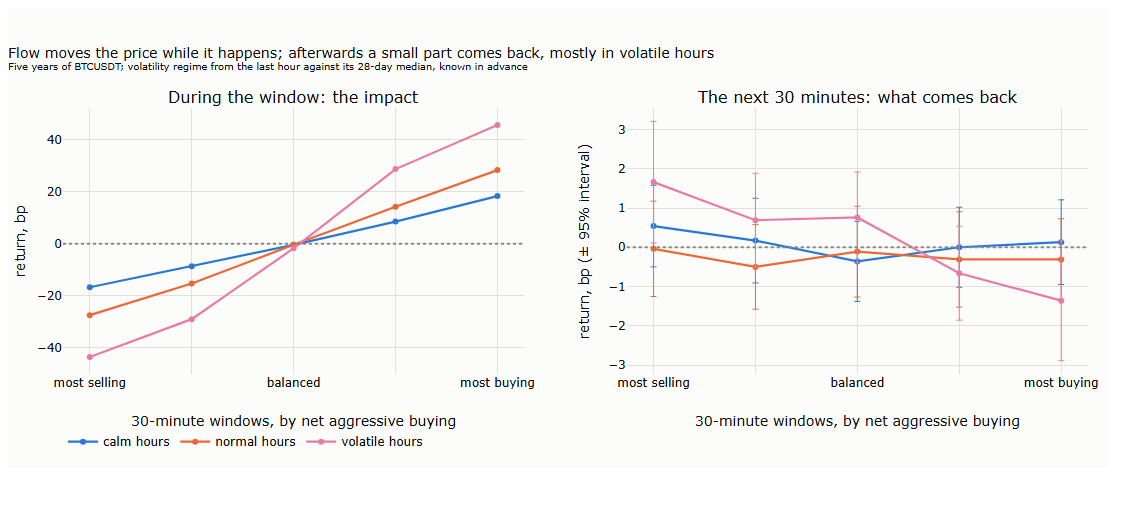

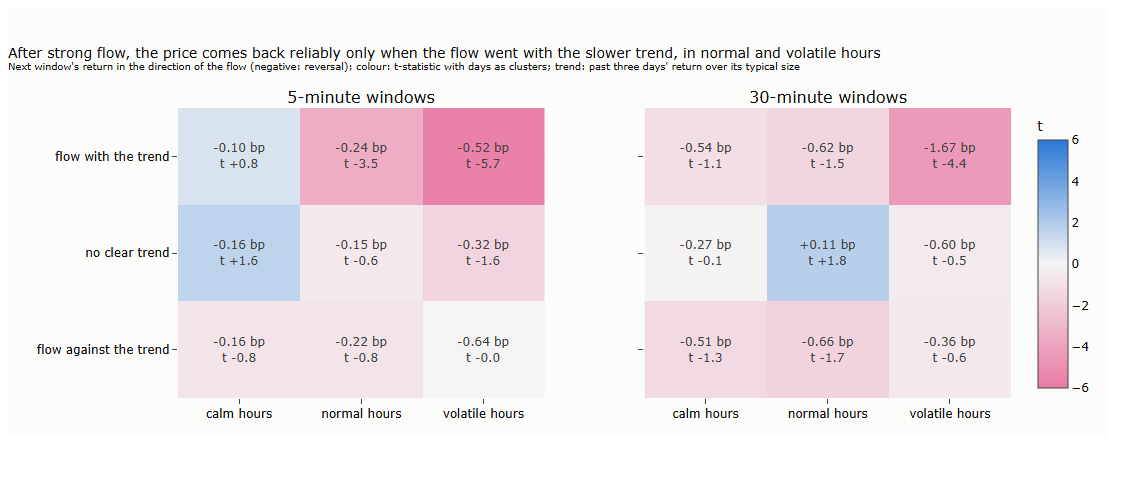

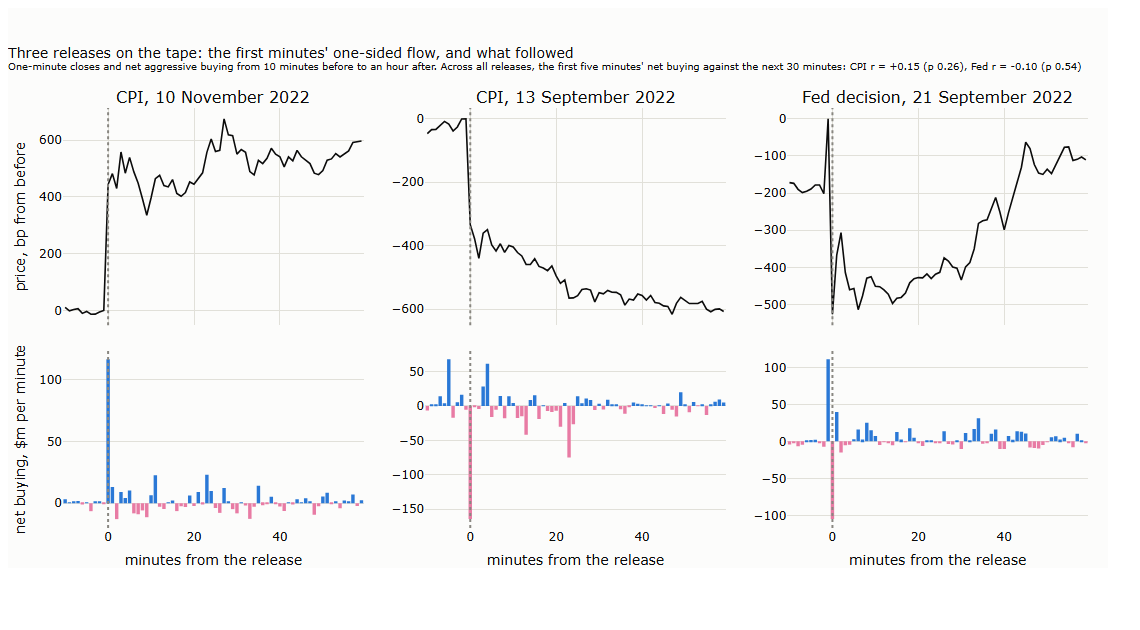

**At all CPI and Fed releases: the first five minutes' flow and move against the next thirty minutes (correlations)**

release,n,flow_vs_next,p_flow,move_vs_next,p_move
str,i64,f64,f64,f64,f64
"""CPI""",59,0.15,0.26,0.45,0.0
"""Fed""",40,-0.1,0.54,-0.32,0.04


In [2]:
run("l15_flow.py"); run("l15_flow_matrix.py"); run("l15_s2_charts.py")
pictures("15_01_impact_and_after", "15_02_flow_matrix", "15_03_releases")
display(Markdown("**At all CPI and Fed releases: the first five minutes' flow and move against the next thirty minutes (correlations)**"))
pl.DataFrame([{"release": k, **v} for k, v in result("l15_s2_charts.json").items()])

## 2. Sweeps and absorption

Lecture §3. Every aggressive order that moved the price by 5 bp or more; the independent ones (first in each 10-minute block); the price path after
them, with and against the slower trend; the test against moments without a sweep, with days as clusters and the Benjamini-Hochberg correction.
Figure 15_04.

l15_sweeps_matrix.py: 4 s


l15_sweeps_checks.py: 4 s


l15_s3_charts.py: 6 s


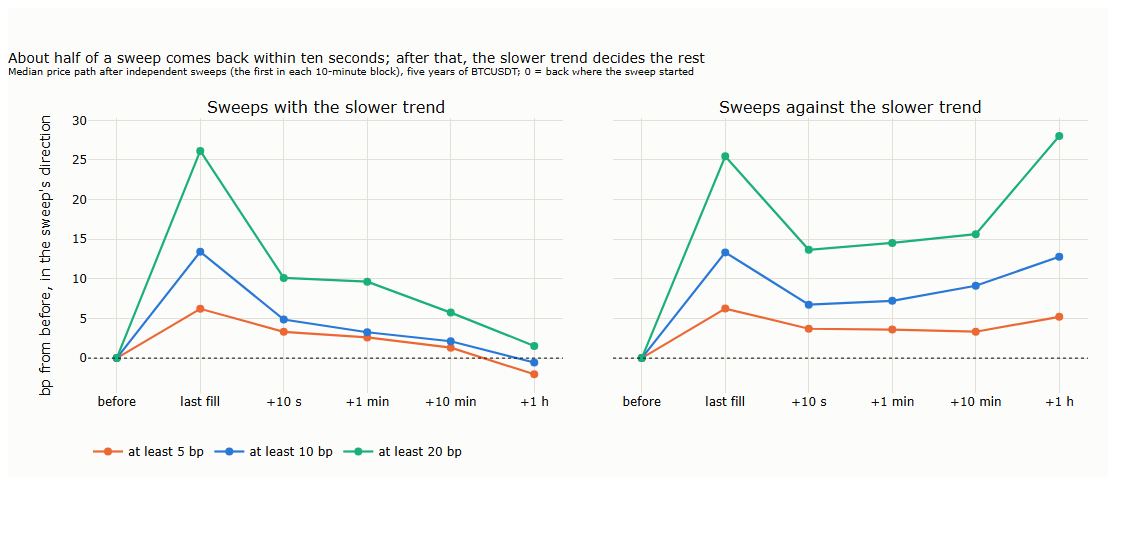

**Return in the trend's direction after the sweep's last fill, minus the regime-matched control, bp**

min_bp,block,rel,h,n,diff,t,q_bh
i64,i64,str,str,i64,f64,f64,f64
5,10,"""against""","""10m""",9396,2.8,4.9,0.0
5,10,"""against""","""1h""",9396,1.2,0.7,0.4925
5,10,"""with""","""10m""",9613,-4.8,-8.8,0.0
5,10,"""with""","""1h""",9613,-7.4,-4.3,0.0
10,10,"""against""","""10m""",2807,4.1,3.4,0.001
10,10,"""against""","""1h""",2807,-1.6,-0.6,0.5331
10,10,"""with""","""10m""",2998,-11.4,-9.9,0.0
10,10,"""with""","""1h""",2998,-14.8,-5.6,0.0
20,10,"""against""","""10m""",783,7.5,2.4,0.0236


In [3]:
if RUN_HEAVY:
    run("l15_sweeps.py")
run("l15_sweeps_matrix.py"); run("l15_sweeps_checks.py"); run("l15_s3_charts.py")
pictures("15_04_sweep_absorption")
display(Markdown("**Return in the trend's direction after the sweep's last fill, minus the regime-matched control, bp**"))
pl.DataFrame(result("l15_sweeps_checks.json")["pooled"]).select("min_bp", "block", "rel", "h", "n", "diff", "t", "q_bh")

## 3. Cascades: fuel and spark

Lecture §4. A cascade is an hour whose move, over its typical size, is in the top 1%. Ten warnings, each tested beyond the last hour's own volatility,
with cut-offs from 2021-2024 and a test on 2025-2026; then the checks on direction and extremes. Figures 15_05 and 15_06.

l15_cascades.py: 8 s


l15_cascades_checks.py: 1 s


l15_s4_charts.py: 4 s


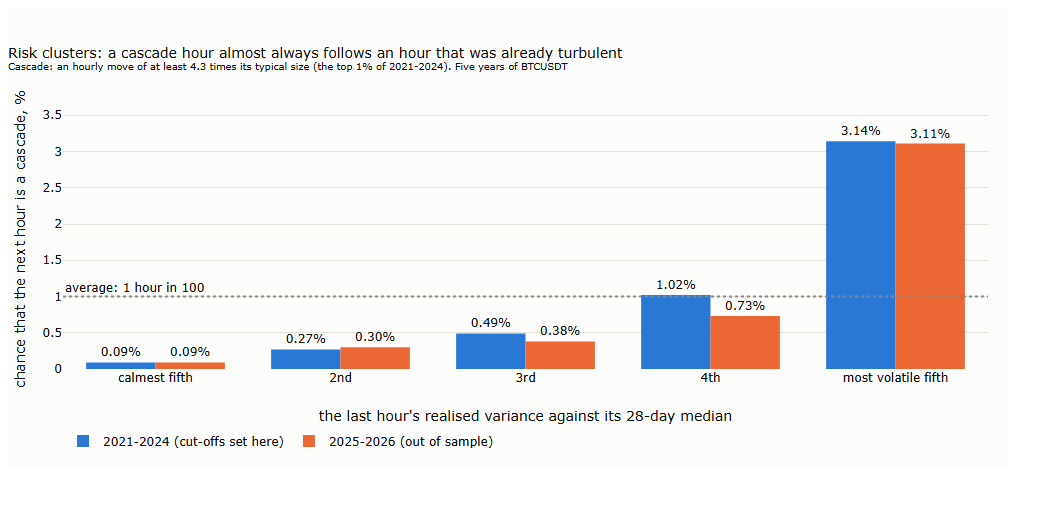

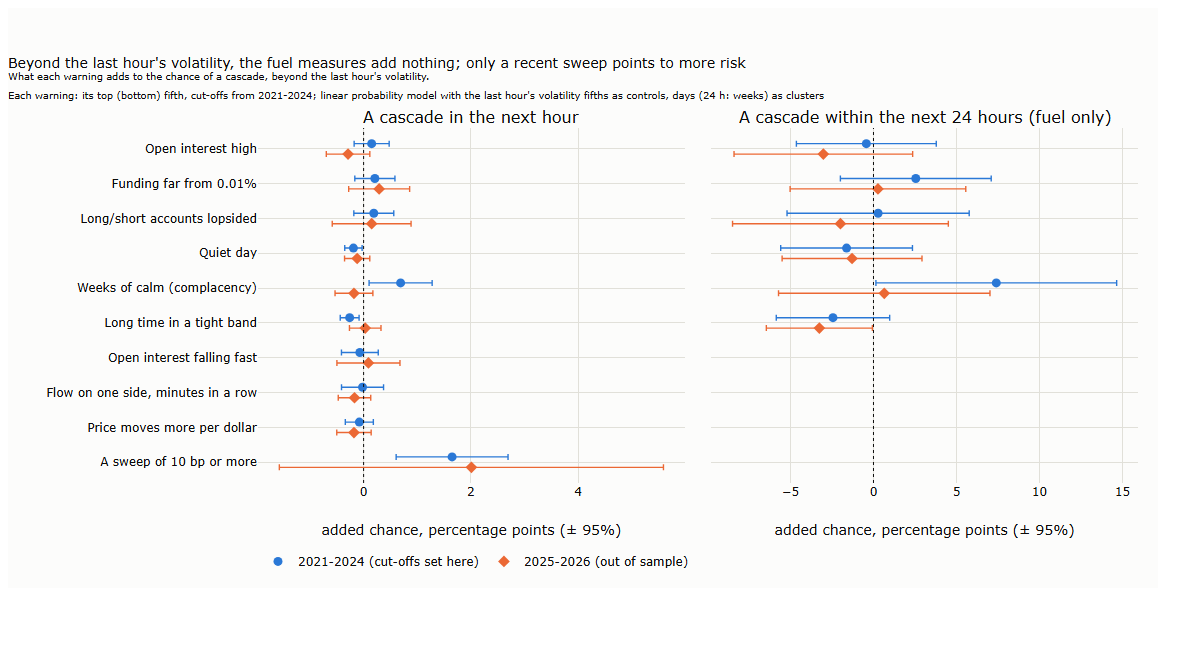

**Chance that the next hour is a cascade, % by fifth of the last hour's volatility:** {'2021-2024': {'0': 0.09, '1': 0.27, '2': 0.49, '3': 1.02, '4': 3.14}, '2025-2026': {'0': 0.09, '1': 0.3, '2': 0.38, '3': 0.73, '4': 3.11}}

warning,horizon,sample,flagged,lift,added_pp,t
str,str,str,f64,f64,f64,f64
"""F1 open interest""","""1 h""","""2021-2024""",0.2,1.14,0.15,0.9
"""F1 open interest""","""1 h""","""2025-2026""",0.168,0.79,-0.29,-1.4
"""F1 open interest""","""24 h""","""2021-2024""",0.2,0.97,-0.43,-0.2
"""F1 open interest""","""24 h""","""2025-2026""",0.168,0.86,-3.02,-1.1
"""F2 funding""","""1 h""","""2021-2024""",0.2,1.42,0.21,1.1
"""F2 funding""","""1 h""","""2025-2026""",0.206,1.31,0.29,1.0
"""F2 funding""","""24 h""","""2021-2024""",0.2,1.25,2.55,1.1
"""F2 funding""","""24 h""","""2025-2026""",0.206,1.01,0.27,0.1
"""F3 crowding""","""1 h""","""2021-2024""",0.2,1.42,0.19,1.0


In [4]:
if RUN_HEAVY:
    run("l15_metrics_download.py")
run("l15_cascades.py"); run("l15_cascades_checks.py"); run("l15_s4_charts.py")
pictures("15_05_risk_clusters", "15_06_warnings")
cas = result("l15_cascades.json")
display(Markdown(f"**Chance that the next hour is a cascade, % by fifth of the last hour's volatility:** {cas['control']}"))
pl.DataFrame(cas["warnings"]).select("warning", "horizon", "sample", "flagged", "lift", "added_pp", "t")

## 4. What a trade costs

Lecture §5. The best bid and ask of 80 days (every fourth day, May 2023 to March 2024), matched to every aggressive order: quoted and effective
half-spread, impact and realised spread at 1, 10 and 60 seconds, by order size and volatility regime. Figures 15_07 and 15_08.

l15_costs_analysis.py: 3 s


l15_s5_charts.py: 4 s


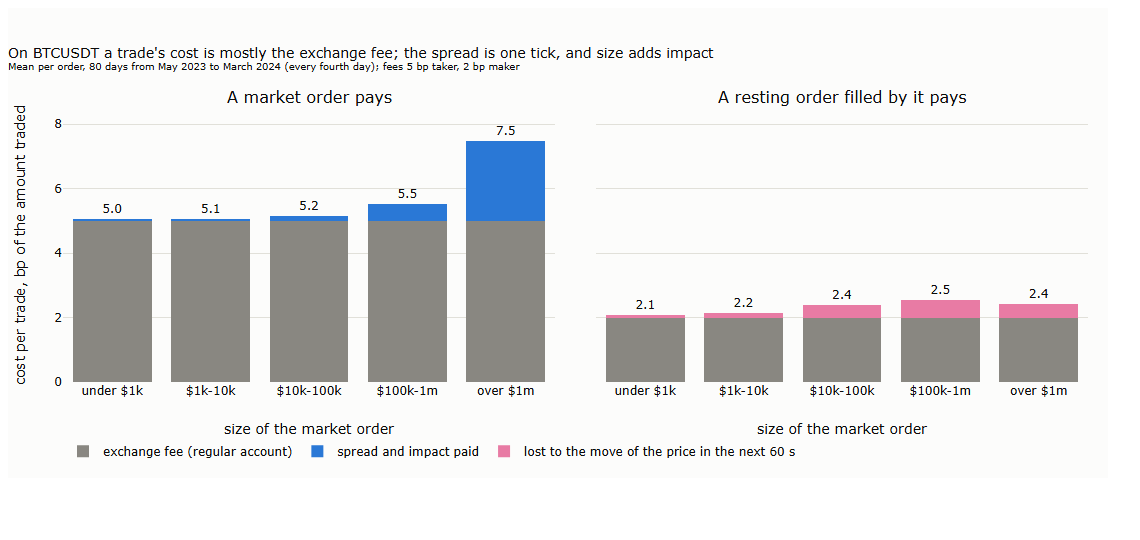

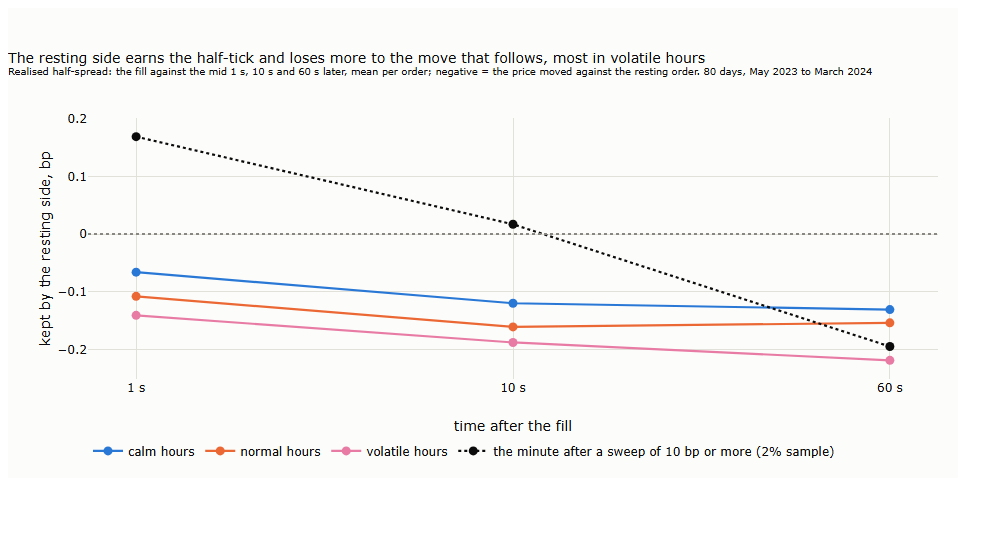

**Days 80, one tick 99.6% of the time, mean quoted half-spread 0.0154 bp**

bucket,orders,quoted,eff,imp_10s,real_10s,real_60s,t_real_10s
str,i64,f64,f64,f64,f64,f64,f64
"""$1k-10k""",16643085,0.031,0.069,0.198,-0.129,-0.152,-20.5
"""$10k-100k""",10127461,0.04,0.151,0.529,-0.379,-0.397,-34.3
"""< $1k""",20683156,0.026,0.039,0.093,-0.054,-0.072,-7.6
"""$100k-1m""",1955191,0.05,0.516,1.099,-0.583,-0.545,-22.1
"""> $1m""",79315,0.079,2.485,3.172,-0.688,-0.427,-7.7


In [5]:
if RUN_HEAVY:
    run("l15_costs.py")
run("l15_costs_analysis.py"); run("l15_s5_charts.py")
pictures("15_07_cost_by_size", "15_08_adverse_selection")
co = result("l15_costs_analysis.json")
display(Markdown(f"**Days {co['days']}, one tick {co['time_share_one_tick']:.1%} of the time, mean quoted half-spread {co['time_mean_quoted_bp']} bp**"))
pl.DataFrame(co["by_size"]).select("bucket", "orders", "quoted", "eff", "imp_10s", "real_10s", "real_60s", "t_real_10s")

## 5. Resting orders

Lecture §6. At every seventh minute, a buy and a mirrored sell: a market order now, or a resting order that chases at a cut-off. Fill rates and the
saving by distance and wait (one-minute bars, five years); what the misses are; the cut-off and re-posting on the tick tape (every tenth day).
Figures 15_09 to 15_11.

l15_resting.py: 42 s


l15_resting_tail.py: 14 s


l15_resting_repost.py: 35 s


l15_s6_charts.py: 7 s


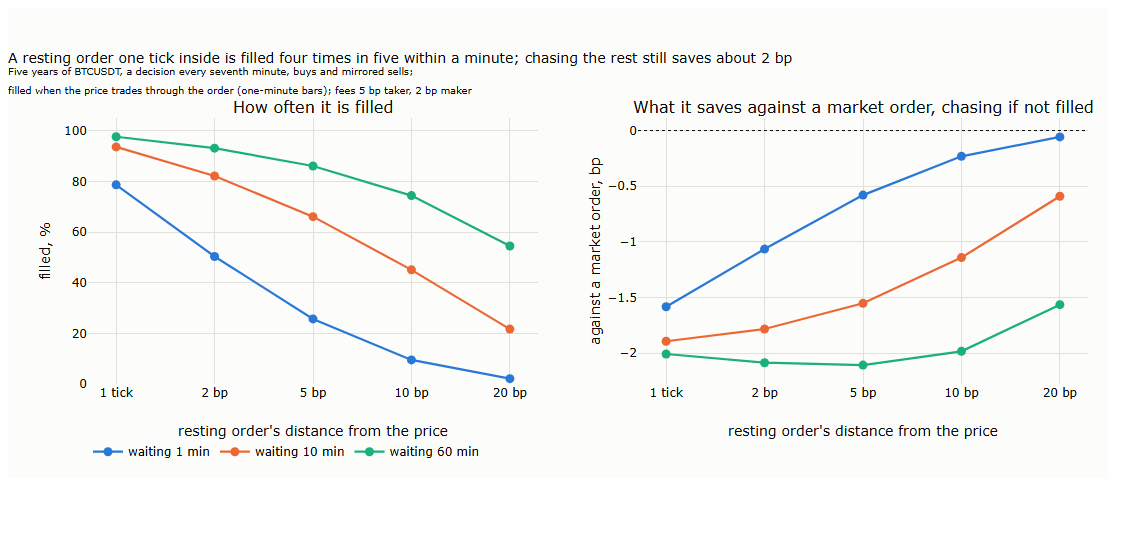

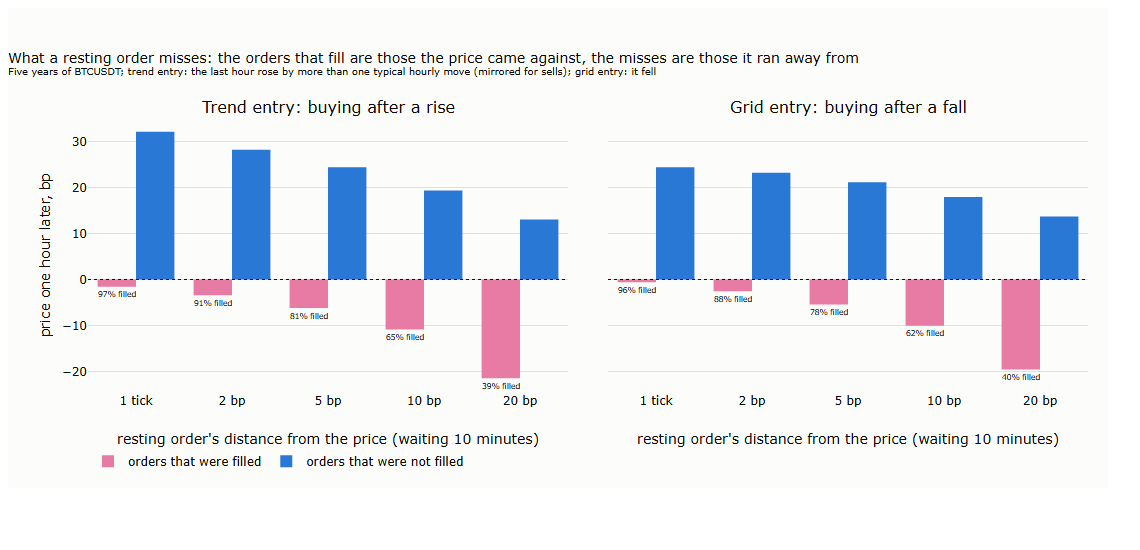

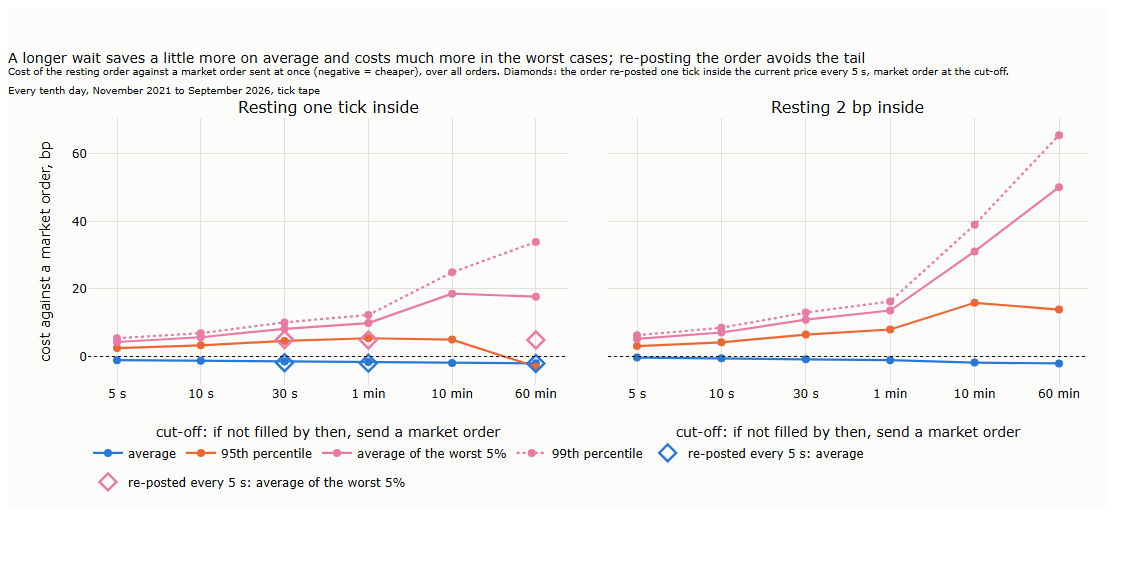

**The cut-off, tick tape: cost against a market order, bp**

offset,cut,n,filled,mean,t,p95,p99,es95,chased,chased_p95
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""1 tick""","""5 s""",74146,0.489,-1.08,-41.7,2.5,5.4,4.3,0.511,3.6
"""1 tick""","""10 s""",74146,0.583,-1.24,-47.5,3.3,6.9,5.7,0.417,5.1
"""1 tick""","""30 s""",74146,0.719,-1.47,-60.2,4.6,10.1,8.2,0.281,8.8
"""1 tick""","""1 min""",74146,0.786,-1.6,-65.9,5.4,12.3,9.9,0.214,11.9
"""1 tick""","""10 min""",74146,0.935,-1.9,-76.5,5.0,24.9,18.6,0.065,45.1
"""1 tick""","""60 min""",74146,0.977,-2.02,-55.5,-3.0,33.9,17.7,0.023,117.3
"""2 bp""","""5 s""",74146,0.144,-0.32,-18.9,3.1,6.3,5.2,0.856,3.4
"""2 bp""","""10 s""",74146,0.228,-0.49,-22.9,4.2,8.5,7.1,0.772,4.8
"""2 bp""","""30 s""",74146,0.395,-0.84,-31.3,6.5,13.0,10.9,0.605,8.3


**Re-posted every few seconds**

variant,mean,t,p95,p99,es95,chased,mean_reposts
str,f64,f64,f64,f64,f64,f64,f64
"""re-post every 5 s, market order after 30 s""",-1.83,-67.7,2.6,6.3,5.0,0.13,1.58
"""re-post every 5 s, market order after 60 s""",-1.96,-86.1,2.3,6.4,4.9,0.057,2.06
"""re-post every 5 s, market order after 300 s""",-2.06,-110.3,2.1,6.5,4.9,0.004,2.73
"""re-post every 5 s, market order after 3600 s""",-2.06,-110.7,2.1,6.5,4.9,0.0,2.87
"""re-post every 10 s, market order after 60 s""",-1.92,-88.4,2.8,7.5,5.9,0.065,1.07
"""re-post every 10 s, market order after 300 s""",-2.03,-117.5,2.5,7.6,5.8,0.004,1.43


In [6]:
run("l15_resting.py"); run("l15_resting_tail.py"); run("l15_resting_repost.py"); run("l15_s6_charts.py")
pictures("15_09_resting_fill_and_saving", "15_10_resting_what_it_misses", "15_11_resting_cutoff")
display(Markdown("**The cut-off, tick tape: cost against a market order, bp**"))
display(pl.DataFrame(result("l15_resting_tail.json")))
display(Markdown("**Re-posted every few seconds**"))
pl.DataFrame(result("l15_resting_repost.json"))

## 6. Capacity: impact and funding

Lecture §7 and the appendix. Daily volume and volatility by year; the capacity map from the square-root law; funding against interest on the spare
cash; long spot against long perpetual (the spot candles are downloaded on first run); aggregate impact on the tape. Figures 15_12 to 15_15.

l15_capacity.py: 12 s


l15_perp_vs_spot.py: 1 s


l15_s7_charts.py: 7 s


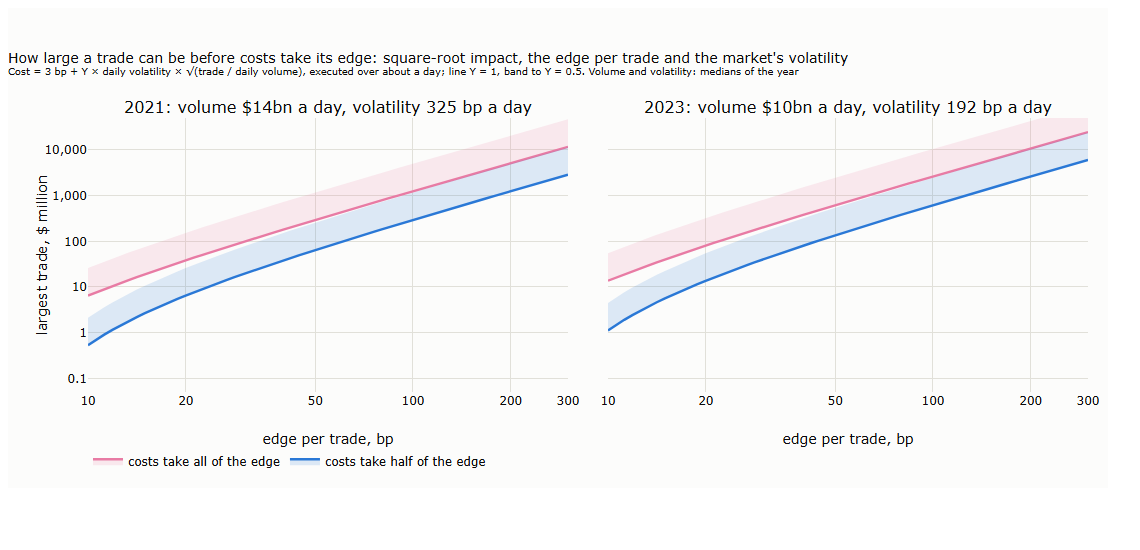

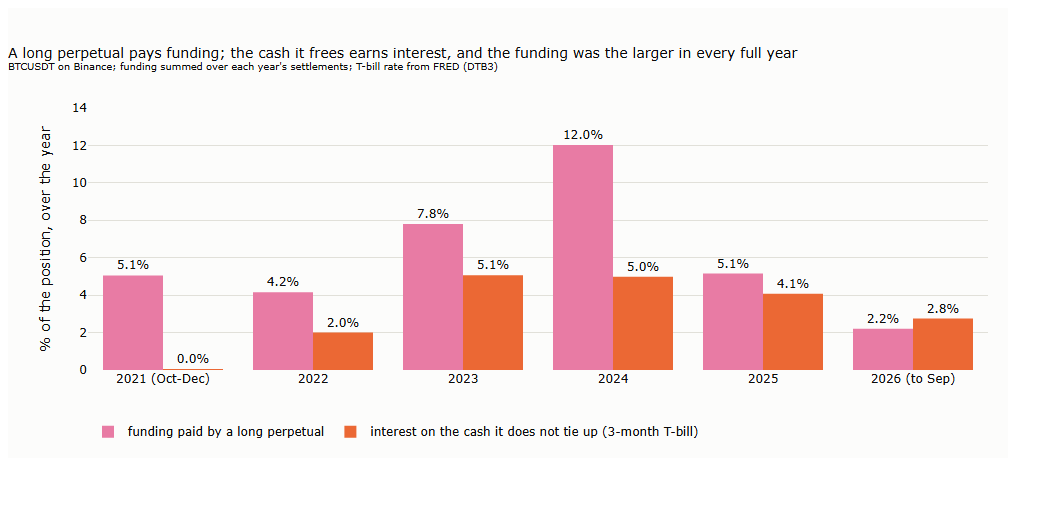

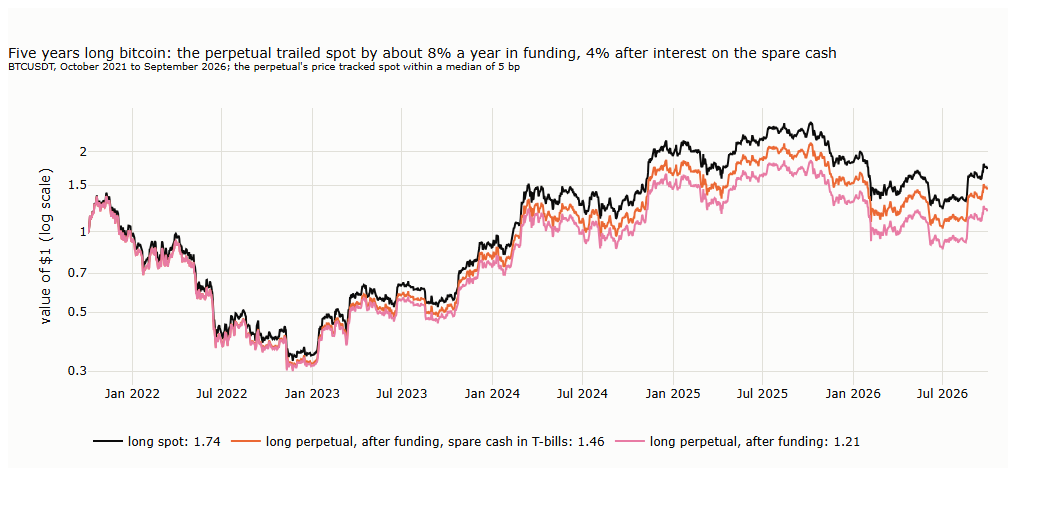

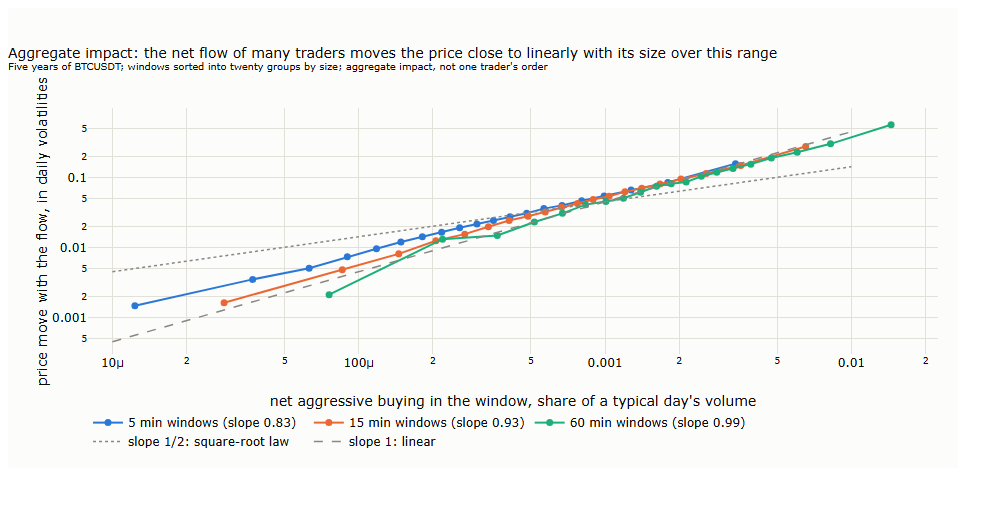

year,V_bn_median,sigma_bp_median
i64,f64,f64
2021,14.0,325.0
2022,12.2,282.0
2023,10.3,192.0
2024,16.2,250.0
2025,15.6,197.0
2026,11.1,205.0


year,spot,perp,perp_cash,funding,cash
i64,f64,f64,f64,f64,f64
2021,-0.0212,-0.0698,-0.0697,0.0505,0.0001
2022,-0.6476,-0.662,-0.6551,0.0415,0.02
2023,1.5374,1.35,1.4718,0.078,0.0506
2024,1.202,0.9508,1.0503,0.1202,0.0498
2025,-0.0464,-0.0943,-0.0567,0.0515,0.0407
2026,-0.0549,-0.0758,-0.05,0.022,0.0275


{'r_spot': 1.737033721971499,
 'r_perp_px': 1.7367011096763965,
 'r_perp': 1.2064866135022416,
 'r_perp_cash': 1.4570817260536562}

In [7]:
run("l15_capacity.py"); run("l15_perp_vs_spot.py"); run("l15_s7_charts.py")
pictures("15_12_capacity", "15_13_funding", "15_14_perp_vs_spot", "15_15_aggregate_impact")
cap, pv = result("l15_capacity.json"), result("l15_perp_vs_spot.json")
display(pl.DataFrame(cap["by_year"])); display(pl.DataFrame(pv["by_year"]))
pv["growth"]

## 7. A test of your own

The re-posted entry of §6 on one day of your choice, with your own re-post interval and cut-off (exercise 4 of §9.2): at every seventh minute a buy
rests one tick below the last price, is re-posted every `STEP` seconds, and becomes a market order after `CUT` seconds.

In [8]:
from datetime import date, datetime, timezone
from l15_resting_fn import first_through

DAY, STEP, CUT = date(2024, 3, 5), 5, 60          # change: any day of the tape, re-post interval and cut-off in seconds
a = int(datetime(DAY.year, DAY.month, DAY.day, tzinfo=timezone.utc).timestamp() * 1000)
t = (pl.scan_parquet(tape.source("BTCUSDT", DAY.strftime("%Y-%m"))).filter(pl.col("transact_time").is_between(a - 60_000, a + 86_400_000))
     .select("transact_time", "price").collect().sort("transact_time"))
ts, px = t["transact_time"].to_numpy(), t["price"].to_numpy()
dec = a + np.arange(60_000, 86_400_000 - CUT * 1000, 7 * 60_000); p0 = px[np.searchsorted(ts, dec, side="right") - 1]
cost = np.full(len(dec), np.nan); open_ = np.ones(len(dec), bool); s = 0
while open_.any() and s * STEP < CUT:
    idx = np.nonzero(open_)[0]; tk = dec[idx] + s * STEP * 1000
    lim = px[np.searchsorted(ts, tk, side="right") - 1] - 0.1
    hit = first_through(ts, px, tk, lim, 1, min(STEP, CUT - s * STEP) * 1000) >= 0
    cost[idx[hit]] = np.log(lim[hit] / p0[idx[hit]]) * 1e4 + 2.0; open_[idx[hit]] = False; s += 1
idx = np.nonzero(open_)[0]
cost[idx] = np.log(px[np.searchsorted(ts, dec[idx] + CUT * 1000, side="right") - 1] / p0[idx]) * 1e4 + 5.04
saving = cost - 5.04
pl.DataFrame({"decisions": [len(dec)], "sent as market order": [round(float(open_.mean()), 3)], "average against a market order, bp": [round(float(saving.mean()), 2)],
              "worst 5%, bp": [round(float(np.sort(saving)[-max(1, len(saving) // 20):].mean()), 1)]})

decisions,sent as market order,"average against a market order, bp","worst 5%, bp"
i64,f64,f64,f64
206,0.0,-1.82,12.1


Negative is cheaper than a market order sent at once. Compare a calm day with a volatile one, and short re-post intervals with long ones: where does the saving stop growing, and where does the tail start?